In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm
import math

from sklearn.model_selection import train_test_split


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yuanchunhong/university-football-injury-prediction-dataset")

print("Path to dataset files:", path)

100%|██████████| 83.9k/83.9k [00:00<00:00, 324kB/s]

Extracting files...
Path to dataset files: C:\Users\USER\.cache\kagglehub\datasets\yuanchunhong\university-football-injury-prediction-dataset\versions\2


In [3]:
from pathlib import Path

csv_files = sorted(Path(path).rglob("*.csv"))

# Data Reading

In [6]:
df = pd.read_csv(csv_files[0])

print("資料形狀：", df.shape)
display(df.head(10))

資料形狀： (800, 19)


,Age,Height_cm,Weight_kg,Position,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,Injury_Next_Season,BMI
0,22,173,64,Midfielder,11.575308,36,1,77.460279,79.115738,284.487853,91.212476,5.874630,77.599705,8.238293,46.616415,81.472206,1,0,21.383942
1,18,170,67,Midfielder,12.275869,37,2,72.634442,82.541688,250.579249,87.294078,5.796269,94.418987,8.983737,49.368037,81.056677,1,0,23.183391
2,22,186,75,Forward,12.254896,12,2,77.064490,75.943631,269.119918,83.440688,5.731209,70.179176,7.229193,43.132808,64.877457,0,1,21.678807
3,20,172,62,Defender,9.006678,11,1,82.810232,73.878324,226.376412,87.591894,6.220212,83.473824,7.681029,51.528529,89.824744,1,0,20.957274
4,18,172,94,Midfielder,12.683668,10,2,76.772859,76.653043,229.021042,83.125161,5.385958,87.037256,6.728091,52.379718,71.569197,0,1,31.773932
5,23,189,89,Goalkeeper,10.262987,31,2,78.450720,80.927984,265.801623,81.106339,6.354870,86.418954,8.538027,39.929697,74.982476,1,0,24.915316
6,22,189,71,Midfielder,8.069288,5,4,63.045009,75.032030,269.099907,76.787369,6.458297,65.179995,7.339327,75.039112,65.790192,0,1,19.876263
7,23,184,75,Goalkeeper,6.407939,26,0,77.566677,76.947213,226.966431,93.317382,6.161460,79.260417,8.072895,25.783371,89.782578,0,0,22.152647
8,22,174,71,Midfielder,10.554931,23,0,78.877905,89.584501,240.745054,80.898575,6.199281,77.152290,7.661190,52.581600,78.587201,1,0,23.450918
9,23,185,76,Midfielder,11.899732,22,0,83.194761,82.244364,259.628161,89.077577,6.206694,90.396480,6.035505,55.049722,83.947949,1,0,22.205990


In [8]:
print("=== 欄位名稱 ===")
print(df.columns.tolist())

print("\n=== 資料型態 ===")
df.info()

print("\n=== 缺失值 ===")
display(df.isna().sum().to_frame("Missing_Count"))

=== 欄位名稱 ===
['Age', 'Height_cm', 'Weight_kg', 'Position', 'Training_Hours_Per_Week', 'Matches_Played_Past_Season', 'Previous_Injury_Count', 'Knee_Strength_Score', 'Hamstring_Flexibility', 'Reaction_Time_ms', 'Balance_Test_Score', 'Sprint_Speed_10m_s', 'Agility_Score', 'Sleep_Hours_Per_Night', 'Stress_Level_Score', 'Nutrition_Quality_Score', 'Warmup_Routine_Adherence', 'Injury_Next_Season', 'BMI']

=== 資料型態 ===
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         800 non-null    int64  
 1   Height_cm                   800 non-null    int64  
 2   Weight_kg                   800 non-null    int64  
 3   Position                    800 non-null    str    
 4   Training_Hours_Per_Week     800 non-null    float64
 5   Matches_Played_Past_Season  800 non-null    int64  
 6   Previous_Injury_Count       80

,Missing_Count
Age,0
Height_cm,0
Weight_kg,0
Position,0
Training_Hours_Per_Week,0
Matches_Played_Past_Season,0
Previous_Injury_Count,0
Knee_Strength_Score,0
Hamstring_Flexibility,0
Reaction_Time_ms,0


In [9]:
print("=== Injury Next Season ===")

display(
    pd.DataFrame({
        "Count": df["Injury_Next_Season"].value_counts().sort_index(),
        "Percentage": (
            df["Injury_Next_Season"]
            .value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)
    })
)

=== Injury Next Season ===


,Count,Percentage
Injury_Next_Season,,
0,400,50.0
1,400,50.0


In [10]:
for col in ["Position", "Warmup_Routine_Adherence"]:
    print(f"\n=== {col} ===")
    display(df[col].value_counts(dropna=False))


=== Position ===


Position
Midfielder    213
Defender      204
Forward       197
Goalkeeper    186
Name: count, dtype: int64


=== Warmup_Routine_Adherence ===


Warmup_Routine_Adherence
1    478
0    322
Name: count, dtype: int64

In [12]:
# 檢查完全重複的資料
print("完全重複列數：", df.duplicated().sum())

# 不考慮 Y，檢查相同 X 是否重複
X_columns = df.columns.drop("Injury_Next_Season")

print(
    "相同特徵組合的重複列數：",
    df.duplicated(subset=X_columns).sum()
)

# 檢查類別和數值範圍
display(df.describe(include="all").T)

完全重複列數： 0
相同特徵組合的重複列數： 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,800.0,NaN,NaN,NaN,21.135,1.991037,18.0,19.0,21.0,23.0,24.0
Height_cm,800.0,NaN,NaN,NaN,177.4075,7.148974,154.0,173.0,177.0,182.0,200.0
Weight_kg,800.0,NaN,NaN,NaN,73.235,9.929276,45.0,66.0,73.0,80.0,105.0
Position,800,4,Midfielder,213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Training_Hours_Per_Week,800.0,NaN,NaN,NaN,9.95115,2.610395,5.0,8.127151,9.89571,11.53514,18.866608
Matches_Played_Past_Season,800.0,NaN,NaN,NaN,22.3325,10.311516,5.0,13.0,22.0,32.0,39.0
Previous_Injury_Count,800.0,NaN,NaN,NaN,1.53625,1.292584,0.0,1.0,1.0,2.0,8.0
Knee_Strength_Score,800.0,NaN,NaN,NaN,74.933249,6.672704,52.391351,70.432656,74.997933,79.632391,93.900051
Hamstring_Flexibility,800.0,NaN,NaN,NaN,79.154123,6.782332,58.180381,74.495959,79.187909,83.813179,100.0
Reaction_Time_ms,800.0,NaN,NaN,NaN,249.423244,22.532387,180.0,234.089585,249.127328,265.105082,306.730851


## continuous varable distribution

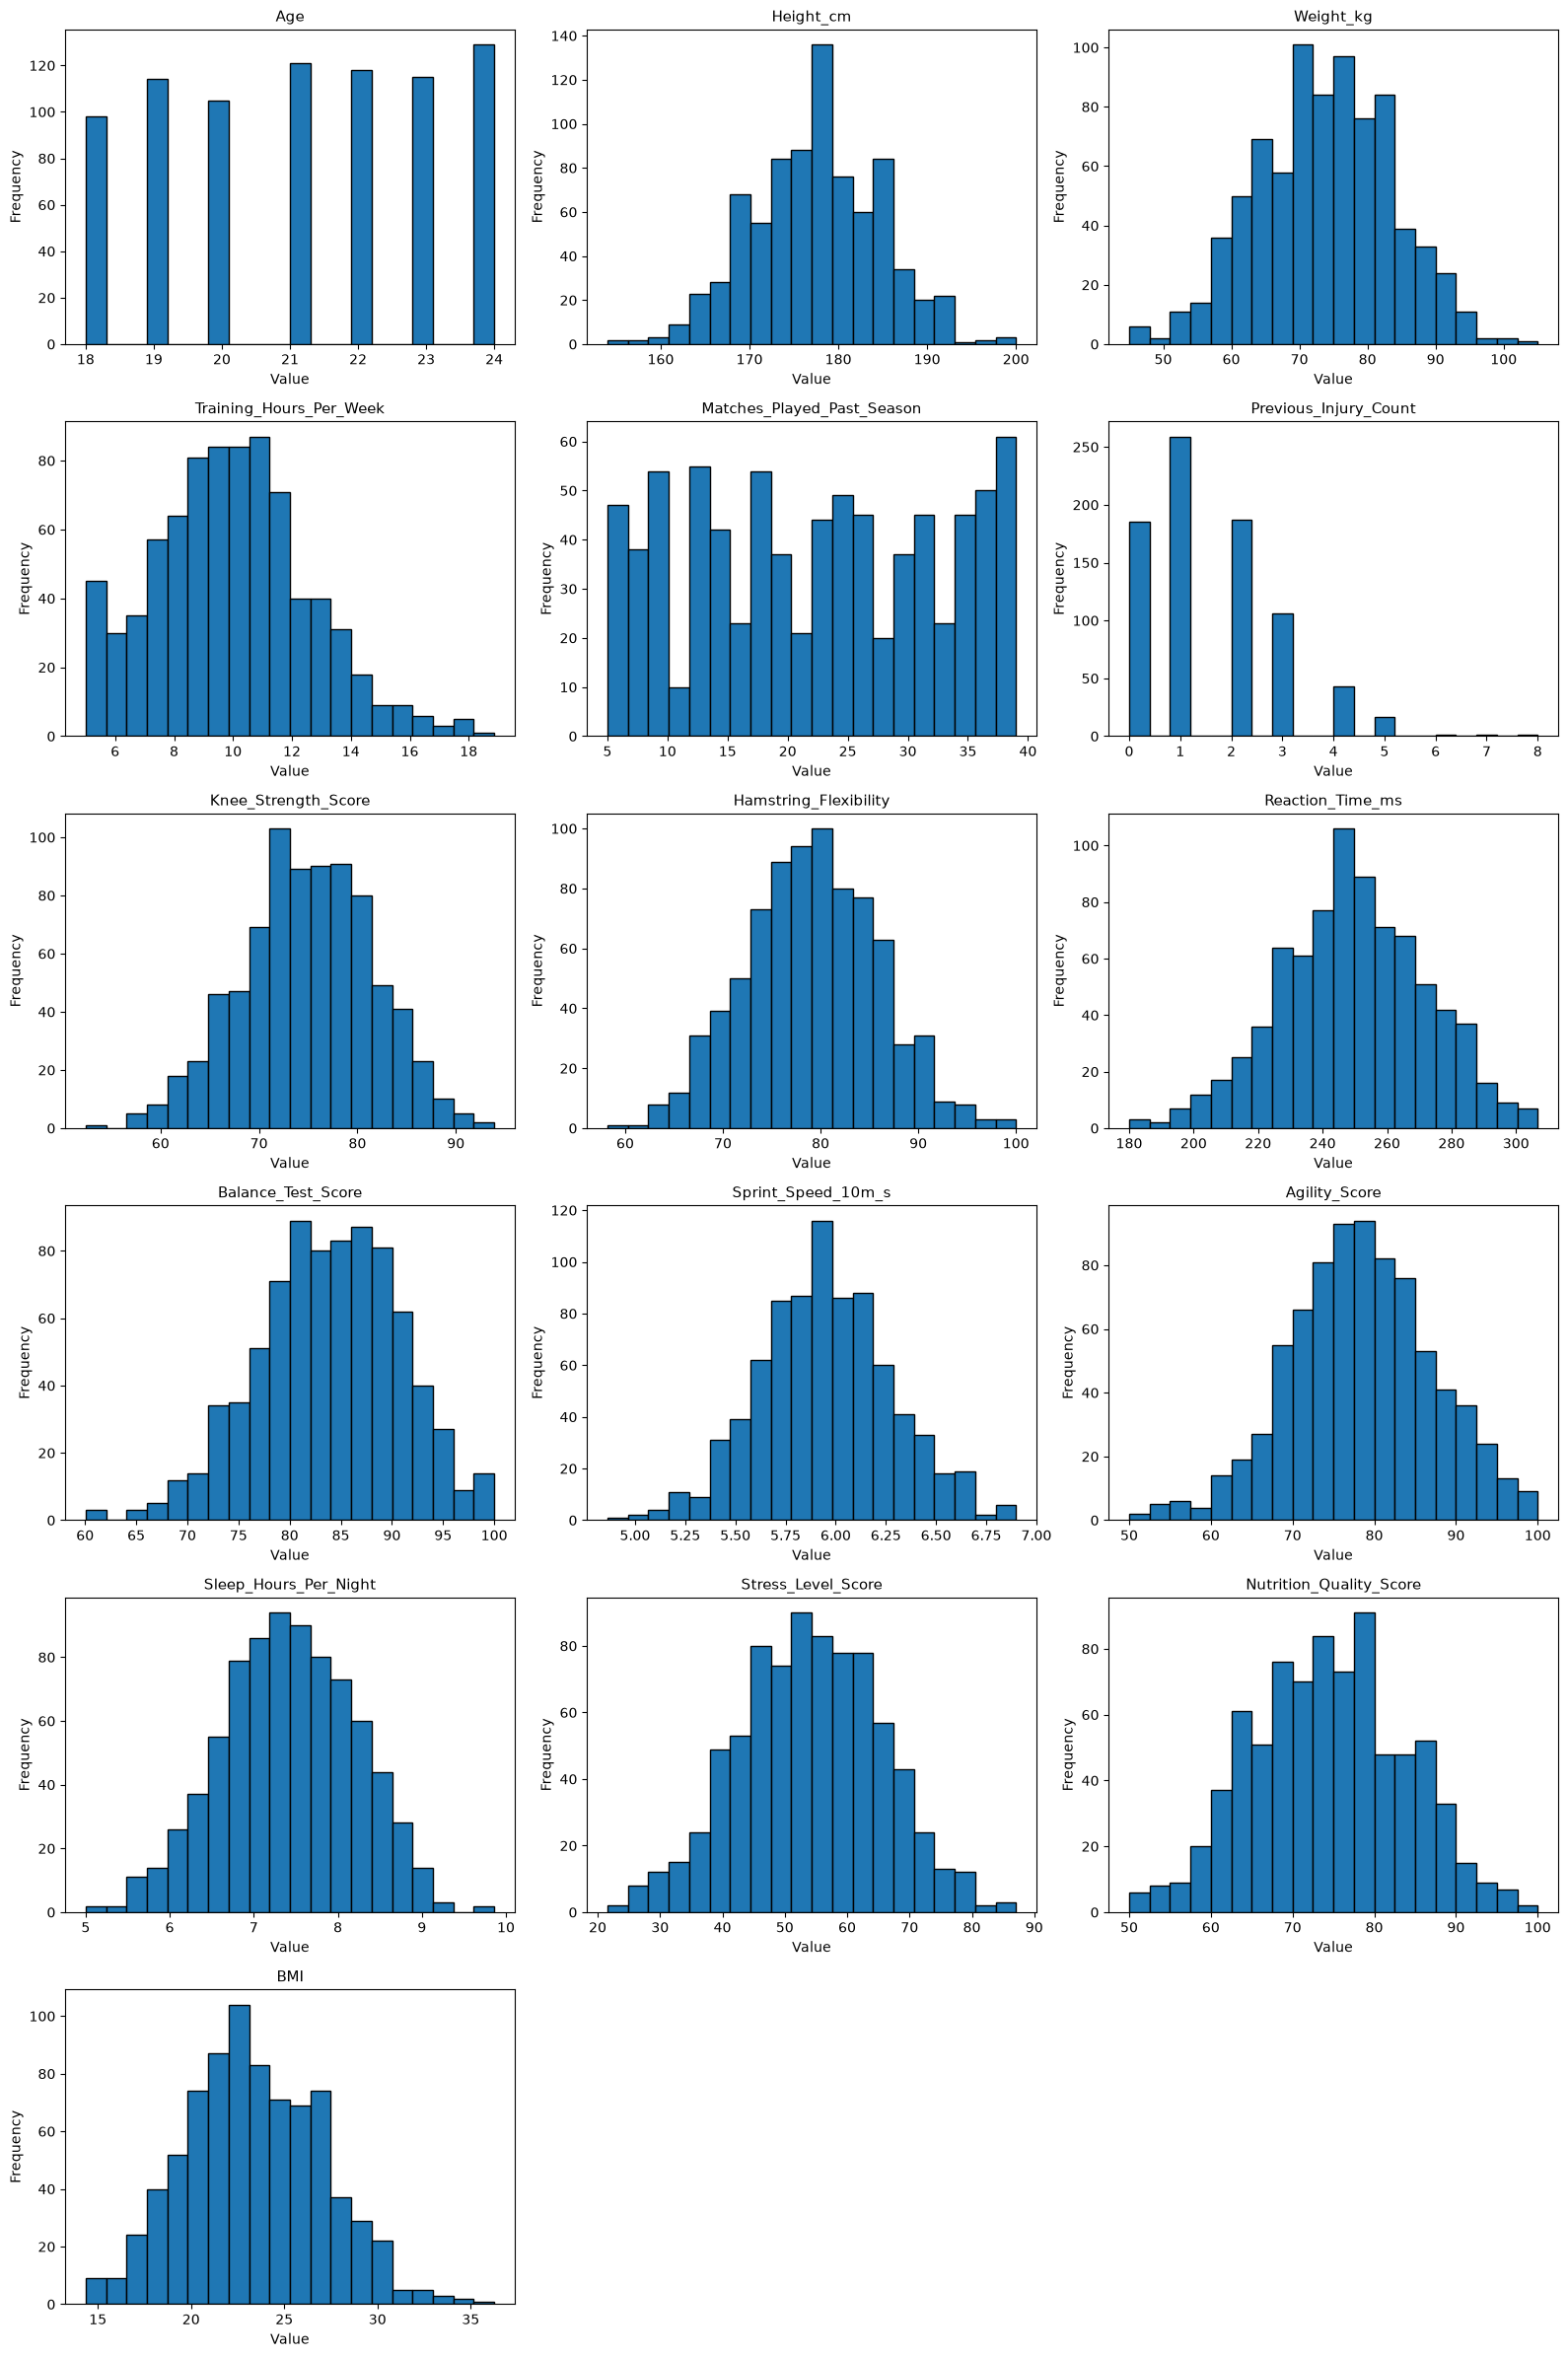

In [14]:
# 選擇數值型自變數
numeric_cols = df.select_dtypes(include="number").columns.tolist()

# 排除二元類別型變數與應變數
numeric_cols = [
    col for col in numeric_cols
    if col not in [
        "Warmup_Routine_Adherence",
        "Injury_Next_Season"
    ]
]

# 畫出所有數值型變數的直方圖
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(
        df[col],
        bins=20,
        edgecolor="black"
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

# 移除空白子圖
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [15]:
outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "Variable": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage": round(outliers.mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(
    outlier_df.sort_values(
        "Outlier Percentage",
        ascending=False
    )
)

,Variable,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
5,Previous_Injury_Count,-0.50,3.50,63,7.88
1,Height_cm,159.50,195.50,11,1.38
3,Training_Hours_Per_Week,3.02,16.65,10,1.25
10,Sprint_Speed_10m_s,5.09,6.80,9,1.12
11,Agility_Score,55.55,101.22,7,0.88
7,Hamstring_Flexibility,60.52,97.79,4,0.50
8,Reaction_Time_ms,187.57,311.63,3,0.38
9,Balance_Test_Score,64.30,103.63,3,0.38
15,BMI,12.93,33.88,3,0.38
12,Sleep_Hours_Per_Night,5.14,9.70,2,0.25


# Split Data

In [ ]:
# 原始資料
data = df.copy()

# 使用分層抽樣
# 第一次切分：85% 開發資料、15% Testing
train_val, test = train_test_split(
    data,
    test_size=0.15,
    random_state=42,                    # 確保每次切分結果一致
    stratify=data["Injury_Next_Season"] # 根據y的比例分層
)

# 第二次切分：開發資料中取出 120 筆 Validation
train, val = train_test_split(
    train_val,
    test_size=120,
    random_state=42,
    stratify=train_val["Injury_Next_Season"]
)

# 整理各資料集資訊
summary = []

for name, subset in [
    ("Training", train),
    ("Validation", val),
    ("Testing", test)
]:
    summary.append({
        "Dataset": name,
        "Samples": len(subset),
        "Not Injured (0)": (
            subset["Injury_Next_Season"] == 0
        ).sum(),
        "Injured (1)": (
            subset["Injury_Next_Season"] == 1
        ).sum()
    })

display(pd.DataFrame(summary))

,Dataset,Samples,Not Injured (0),Injured (1)
0,Training,560,280,280
1,Validation,120,60,60
2,Testing,120,60,60


In [18]:
assert set(train.index).isdisjoint(val.index)
assert set(train.index).isdisjoint(test.index)
assert set(val.index).isdisjoint(test.index)

print("三組資料切分成功，沒有重疊樣本！")

三組資料切分成功，沒有重疊樣本！
